# Week 2 Homework

## Importing the data

In [2]:
!wget https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv

--2026-10-04 16:42:15--  https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.109.133, 185.199.110.133, 185.199.111.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.109.133|:443... connected.


HTTP request sent, awaiting response... 200 OK
Length: 635180 (620K) [text/plain]
Saving to: ‘car_fuel_efficiency_2026.csv’

car_fuel_efficiency 100%[===================>] 620.29K  --.-KB/s    in 0.1s    

2026-10-04 16:42:15 (6.32 MB/s) - ‘car_fuel_efficiency_2026.csv’ saved [635180/635180]



## EDA

In [3]:
import pandas as pd
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           10000 non-null  int64  
 1   origin               10000 non-null  str    
 2   fuel_type            10000 non-null  str    
 3   drivetrain           10000 non-null  str    
 4   num_doors            10000 non-null  int64  
 5   engine_displacement  10000 non-null  int64  
 6   num_cylinders        10000 non-null  int64  
 7   horsepower           9123 non-null   float64
 8   vehicle_weight       10000 non-null  int64  
 9   acceleration         9736 non-null   float64
 10  fuel_efficiency_mpg  10000 non-null  float64
dtypes: float64(3), int64(5), str(3)
memory usage: 859.5 KB


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

<Axes: xlabel='fuel_efficiency_mpg', ylabel='Count'>

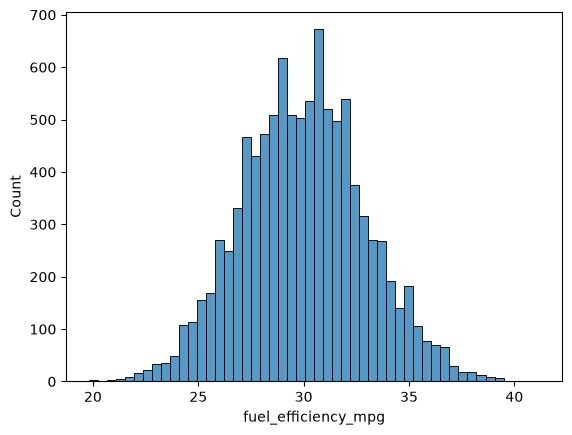

In [6]:
# Fuel efficiency histplot
sns.histplot(df['fuel_efficiency_mpg'], bins=50)

<Axes: xlabel='model_year', ylabel='Count'>

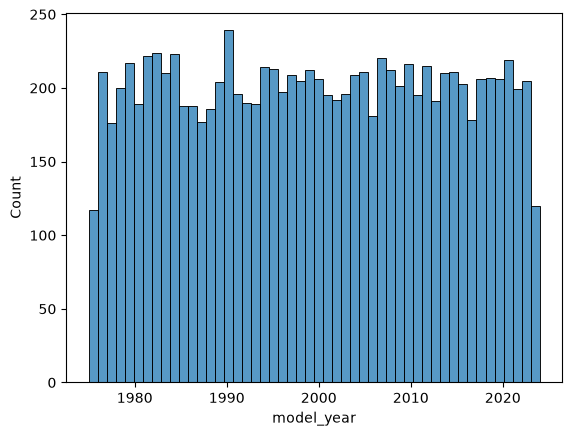

In [10]:
# cars per year
sns.histplot(df['model_year'], bins=50)

<Axes: xlabel='vehicle_weight', ylabel='Count'>

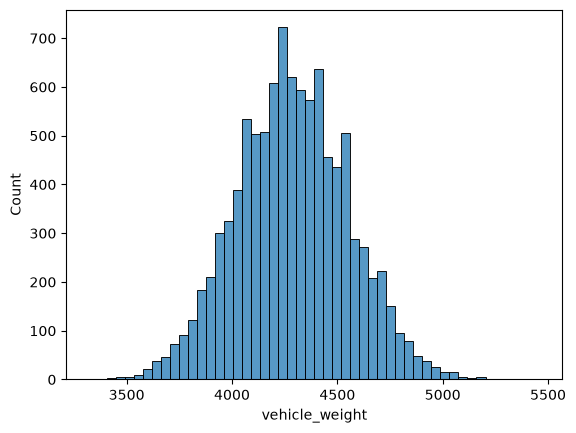

In [34]:
sns.histplot(df['vehicle_weight'], bins=50)

In [11]:
# information about numeric columns
df.describe()

,model_year,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
count,10000.000000,10000.00000,10000.000000,10000.000000,9123.000000,10000.000000,9736.000000,10000.000000
mean,1999.549500,3.50400,2268.807000,6.035200,254.446016,4286.754000,18.888044,29.997700
std,14.207925,0.95209,183.447355,0.542578,22.844613,266.212491,1.279543,2.930245
min,1975.000000,2.00000,1590.000000,4.000000,171.000000,3320.000000,14.000000,19.800000
25%,1987.000000,3.00000,2150.000000,6.000000,239.000000,4110.000000,18.000000,28.000000
50%,2000.000000,4.00000,2270.000000,6.000000,254.000000,4280.000000,18.900000,30.000000
75%,2012.000000,4.00000,2390.000000,6.000000,270.000000,4470.000000,19.700000,31.900000
max,2024.000000,5.00000,3110.000000,8.000000,334.000000,5460.000000,23.800000,41.200000


In [12]:
display(df['horsepower'].median())

np.float64(254.0)

In [44]:
## Some feature engineering before proceeding:
def feature_engineering(data, fill_strategy, mean_fill = df_train['horsepower'].mean()):
    data = data.reset_index()
    data['age_of_car'] = 2026-df['model_year']

    # Normalize vehicle wt
    data['vehicle_weight_norm'] = (data['vehicle_weight'] - data['vehicle_weight'].min())/(data['vehicle_weight'].max() - data['vehicle_weight'].min())
    data['engine_displacement_norm'] = (data['engine_displacement'] - data['engine_displacement'].min())/(data['engine_displacement'].max() - data['engine_displacement'].min())
    

    # fill data
    if fill_strategy == "zeros":
        data['horsepower'] = data['horsepower'].fillna(0)
    else:
        data['horsepower'] = data['horsepower'].fillna(mean_fill)

    # Normalization of fuel efficiency:
    base_cols = ['engine_displacement_norm', 'horsepower', 'vehicle_weight_norm', 'age_of_car']
    target = ['fuel_efficiency_mpg']

    return data[base_cols].values, data[target].values

# df['age_of_car'] = 2026 - df['model_year']

# normalize 

In [45]:
## Data prep
import numpy as np
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [46]:
df_train.info()

<class 'pandas.DataFrame'>
Index: 6000 entries, 6252 to 3252
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   model_year           6000 non-null   int64  
 1   origin               6000 non-null   str    
 2   fuel_type            6000 non-null   str    
 3   drivetrain           6000 non-null   str    
 4   num_doors            6000 non-null   int64  
 5   engine_displacement  6000 non-null   int64  
 6   num_cylinders        6000 non-null   int64  
 7   horsepower           5462 non-null   float64
 8   vehicle_weight       6000 non-null   int64  
 9   acceleration         5844 non-null   float64
 10  fuel_efficiency_mpg  6000 non-null   float64
dtypes: float64(3), int64(5), str(3)
memory usage: 562.5 KB


In [47]:
X_train_0, y_train = feature_engineering(df_train, 'zeros')
X_train_mean, y_train = feature_engineering(df_train, 'mean')


In [48]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

In [49]:
def rmse(y, y_pred):
    se = (y - y_pred) ** 2
    mse = se.mean()
    return np.sqrt(mse)

In [54]:
# With zeros
w00, w_0 = train_linear_regression(X_train_0, y_train)
y_pred_zero_fill = w00 + X_train_0.dot(w_0)

In [51]:
rmse_zero = rmse(y_train, y_pred_zero_fill)
print(rmse_zero)

2.591828669936971


In [55]:
# with mean fill
w0_mean, w_mean = train_linear_regression(X_train_mean, y_train)
y_pred_mean_fill = w0_mean+X_train_mean.dot(w_mean)

rmse_mean = rmse(y_train, y_pred_mean_fill)
print(rmse_mean)

2.634244381991116


In [56]:
# Validating the model
X_val_0, y_val = feature_engineering(df_val, 'zeros')
y_pred_0_val = w00 + X_val_0.dot(w_0)
rmse_val_0 = rmse(y_val, y_pred_0_val)
print(rmse_val_0)

2.6753591923202253


In [57]:
X_val_mean, y_val = feature_engineering(df_val, 'mean')
y_pred_mean_val = w0_mean + X_val_mean.dot(w_mean)
rmse_val_mean = rmse(y_val, y_pred_mean_val)
print(rmse_val_mean)

2.679141194671013


In [64]:
## Reguralization
r = [0, 0.01, 0.1, 1, 5, 10, 100]
def train_linear_regression_reg(X, y, r=0.001):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])
    # print(X.shape)
    XTX = X.T.dot(X)
    # print(XTX.shape)
    XTX = XTX + r * np.eye(XTX.shape[0])

    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    
    return w_full[0], w_full[1:]

for rate in r:
    w0, w = train_linear_regression_reg(X_train_0, y_train, r=rate)
    y_pred = w0 + X_val_0.dot(w)
    score = rmse(y_val, y_pred)
    
    print(f"r: {rate}, w0={w0}, score={round(score, 4)}")

r: 0, w0=[33.96411073], score=2.6754
r: 0.01, w0=[33.96234301], score=2.6753
r: 0.1, w0=[33.94644642], score=2.6747
r: 1, w0=[33.78874061], score=2.6695
r: 5, w0=[33.11435722], score=2.6533
r: 10, w0=[32.32730716], score=2.6471
r: 100, w0=[23.82454006], score=3.2888


In [66]:
## Seeding
seeds = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
train_rmse_vals = []
valid_rmse_vals = []

for seed in seeds:
    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    # Split
    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]
    df_test = df.iloc[idx[n_train + n_val:]]

    # feature engineering and prep
    X_train, y_train = feature_engineering(df_train, 'zeros')
    w0, w = train_linear_regression(X_train, y_train)
    y_pred_train = w0+X_train.dot(w)
    train_rmse = rmse(y_train, y_pred_train)
    train_rmse_vals.append(train_rmse)

    X_val, y_val = feature_engineering(df_val,'zeros')
    y_pred_val = w0+X_val.dot(w)
    val_rmse = rmse(y_val, y_pred_val)
    valid_rmse_vals.append(val_rmse)
    print(f"Seed: {seed} | RMSE train: {round(train_rmse,3)} | RMSE val: {round(val_rmse, 3)}\n")

print(f"Std deviation of RMSE of all seeds: {round(np.std(valid_rmse_vals), 3)}")    

Seed: 0 | RMSE train: 2.579 | RMSE val: 2.808

Seed: 1 | RMSE train: 2.588 | RMSE val: 2.646

Seed: 2 | RMSE train: 2.615 | RMSE val: 2.584

Seed: 3 | RMSE train: 2.591 | RMSE val: 2.732

Seed: 4 | RMSE train: 2.613 | RMSE val: 2.68

Seed: 5 | RMSE train: 2.577 | RMSE val: 2.686

Seed: 6 | RMSE train: 2.569 | RMSE val: 2.789

Seed: 7 | RMSE train: 2.606 | RMSE val: 2.598

Seed: 8 | RMSE train: 2.572 | RMSE val: 2.599

Seed: 9 | RMSE train: 2.595 | RMSE val: 2.745

Std deviation of RMSE of all seeds: 0.076


In [67]:
# train using train + val with seed 9
np.random.seed(seed)
idx = np.arange(n)
np.random.shuffle(idx)
n_train = n - n_test

# Split
df_train = df.iloc[idx[:n_train]]
#df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train:]]

# feature engineering and prep
X_train, y_train = feature_engineering(df_train, 'zeros')
w0, w = train_linear_regression(X_train, y_train)
y_pred_train = w0+X_train.dot(w)
train_rmse = rmse(y_train, y_pred_train)

print(train_rmse)
X_test, y_test = feature_engineering(df_test, 'zeros')
y_pred = w0+X_test.dot(w)
test_rmse = rmse(y_test, y_pred)
print(test_rmse)

2.5887038327174112
2.7497931685047967
